# Machine Learning: Unit 2 | Complete Code
**Supervised Learning: Regression & Classification**: linear regression, metrics, logistic regression, k-NN, classification metrics.

Install if needed: `pip install numpy pandas matplotlib seaborn scipy scikit-learn statsmodels`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_auc_score, roc_curve)

## 1. Introduction to Supervised Learning
Standard workflow: `split → fit → predict → evaluate`. Also: overfitting vs underfitting.

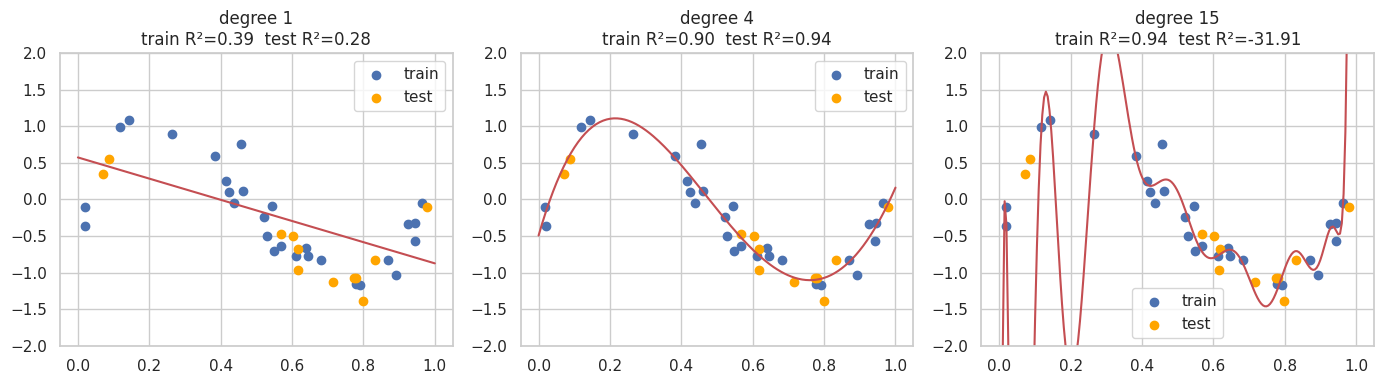

degree 1 = underfit, degree 4 = good fit, degree 15 = overfit


In [2]:
# Overfitting vs Underfitting demo using polynomial regression of different degrees
rng = np.random.RandomState(0)
x = np.sort(rng.uniform(0, 1, 40)); y = np.sin(2 * np.pi * x) + rng.normal(0, 0.25, 40)
Xp = x.reshape(-1, 1)
Xtr, Xte, ytr, yte = train_test_split(Xp, y, test_size=0.3, random_state=1)

xs = np.linspace(0, 1, 200).reshape(-1, 1)
plt.figure(figsize=(14, 4))
for i, deg in enumerate([1, 4, 15], 1):
    m = make_pipeline(PolynomialFeatures(deg), LinearRegression()).fit(Xtr, ytr)
    plt.subplot(1, 3, i)
    plt.scatter(Xtr, ytr, label="train"); plt.scatter(Xte, yte, c="orange", label="test")
    plt.plot(xs, m.predict(xs), "r")
    plt.ylim(-2, 2)
    plt.title(f"degree {deg}\ntrain R²={m.score(Xtr, ytr):.2f}  test R²={m.score(Xte, yte):.2f}")
    plt.legend()
plt.tight_layout(); plt.show()
print("degree 1 = underfit, degree 4 = good fit, degree 15 = overfit")

## 2. Simple Linear Regression

### 2.1 By hand (least squares) and checking against sklearn

In [3]:
# Worked example from the notes
x = np.array([1, 2, 3, 4, 5]); y = np.array([2, 4, 5, 4, 5])
x_bar, y_bar = x.mean(), y.mean()
b1 = np.sum((x - x_bar) * (y - y_bar)) / np.sum((x - x_bar) ** 2)
b0 = y_bar - b1 * x_bar
print(f"slope β1 = {b1}, intercept β0 = {b0}  ->  ŷ = {b0:.1f} + {b1:.1f}x")
print("Prediction at x = 6:", b0 + b1 * 6)

lr = LinearRegression().fit(x.reshape(-1, 1), y)
print("sklearn:", lr.intercept_, lr.coef_[0])

# Residuals and SSE
y_hat = b0 + b1 * x
print("Residuals:", y - y_hat, "| SSE:", np.sum((y - y_hat) ** 2))

slope β1 = 0.6, intercept β0 = 2.2  ->  ŷ = 2.2 + 0.6x
Prediction at x = 6: 5.8
sklearn: 2.2 0.6
Residuals: [-0.8  0.6  1.  -0.6 -0.2] | SSE: 2.3999999999999995


### 2.2 With sklearn: train/test split, evaluate, plot

Intercept (β0): 28.56 | Slope (β1): 6.231
Test R²: 0.9896
Predicted marks for 7.5 hours: 75.29


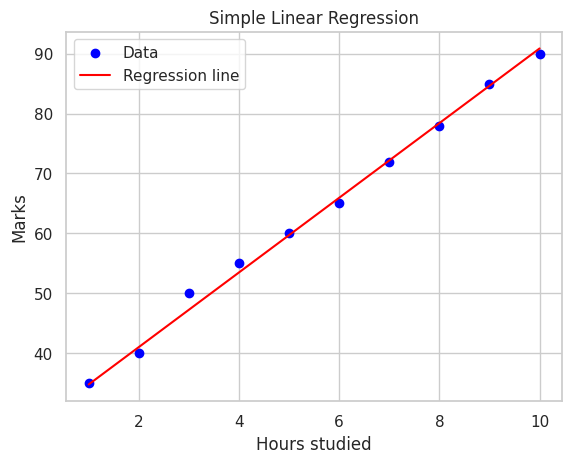

In [4]:
df = pd.DataFrame({"hours": [1,2,3,4,5,6,7,8,9,10], "marks": [35,40,50,55,60,65,72,78,85,90]})
X = df[["hours"]]            # 2-D required by sklearn
y = df["marks"]              # 1-D target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)
model = LinearRegression().fit(X_train, y_train)
print("Intercept (β0):", round(model.intercept_, 3), "| Slope (β1):", round(model.coef_[0], 3))

y_pred = model.predict(X_test)
print("Test R²:", round(r2_score(y_test, y_pred), 4))
print("Predicted marks for 7.5 hours:", model.predict(pd.DataFrame({"hours": [7.5]}))[0].round(2))

plt.scatter(X, y, color="blue", label="Data")
plt.plot(X, model.predict(X), color="red", label="Regression line")
plt.xlabel("Hours studied"); plt.ylabel("Marks"); plt.legend(); plt.title("Simple Linear Regression"); plt.show()

## 3. Multiple Linear Regression

In [5]:
from sklearn.datasets import load_diabetes
d = load_diabetes(as_frame=True); dfm = d.frame
print(dfm.shape); print(dfm.head(3))

X = dfm.drop("target", axis=1); y = dfm["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

mlr = LinearRegression().fit(X_train, y_train)
print("Intercept:", round(mlr.intercept_, 2))
print(pd.Series(mlr.coef_, index=X.columns).sort_values().round(1))

y_pred = mlr.predict(X_test)
print("R²  :", round(r2_score(y_test, y_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))

(442, 11)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
Intercept: 151.35
s1    -931.5
sex   -242.0
age     37.9
s6      48.7
s3     163.4
s4     275.3
bp     347.7
s2     518.1
bmi    542.4
s5     736.2
dtype: float64
R²  : 0.453
RMSE: 53.85


Normal-equation intercept: 151.35 (matches sklearn)
Max coefficient difference: 8.571987564209849e-11


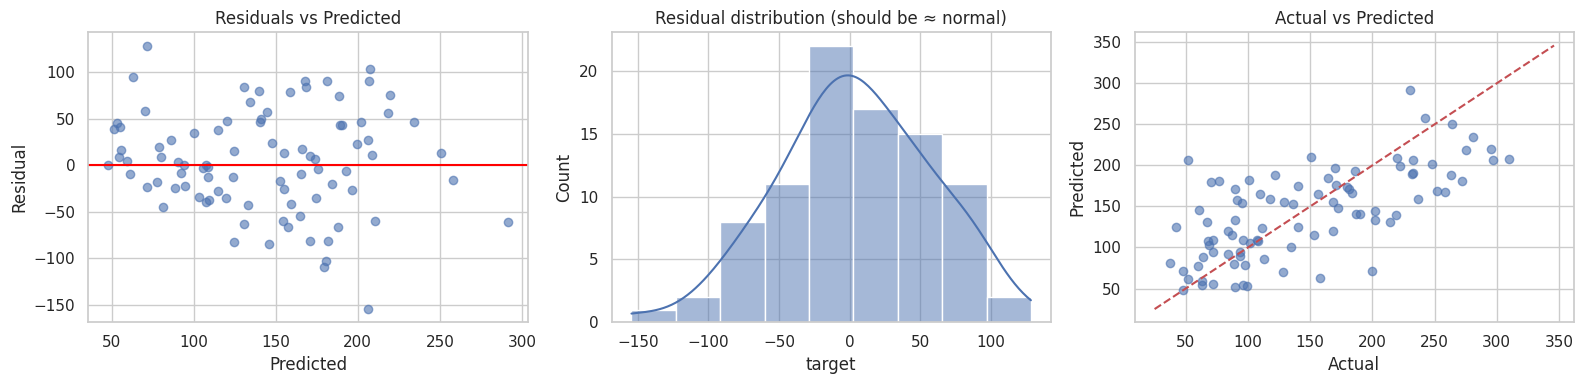

In [6]:
# Verify with the Normal Equation: β = (XᵀX)⁻¹ Xᵀ y
Xb = np.c_[np.ones(len(X_train)), X_train.values]
beta = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ y_train.values
print("Normal-equation intercept:", beta[0].round(2), "(matches sklearn)")
print("Max coefficient difference:", np.abs(beta[1:] - mlr.coef_).max())

# Assumption checks: residual plot + normality of residuals
res = y_test - y_pred
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(y_pred, res, alpha=0.6); ax[0].axhline(0, color="red"); ax[0].set(title="Residuals vs Predicted", xlabel="Predicted", ylabel="Residual")
sns.histplot(res, kde=True, ax=ax[1]); ax[1].set_title("Residual distribution (should be ≈ normal)")
ax[2].scatter(y_test, y_pred, alpha=0.6); ax[2].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[2].set(title="Actual vs Predicted", xlabel="Actual", ylabel="Predicted")
plt.tight_layout(); plt.show()

age     1.22
sex     1.28
bmi     1.51
bp      1.46
s1     59.20
s2     39.19
s3     15.40
s4      8.89
s5     10.08
s6      1.48
dtype: float64


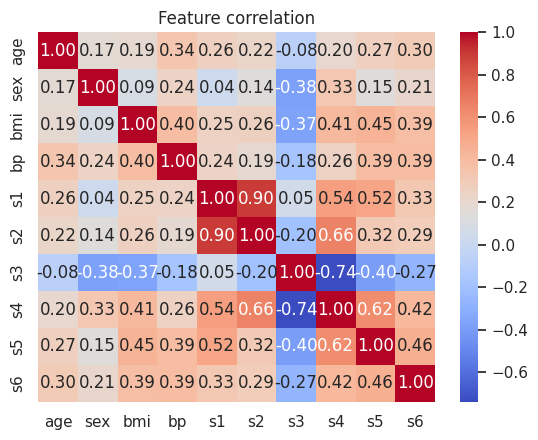

   area  price  city_B  city_C
0   800     40   False   False
1  1000     55    True   False
2  1200     62   False   False
3  1500     85   False    True
4   900     48    True   False
5  1100     66   False    True
{'area': np.float64(0.052), 'city_B': np.float64(3.091), 'city_C': np.float64(8.955)}


In [7]:
# Multicollinearity: Variance Inflation Factor (VIF < 5 good, > 10 problem)
try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
    print(vif.round(2))
except ImportError:
    print("pip install statsmodels to compute VIF")
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="coolwarm"); plt.title("Feature correlation"); plt.show()

# Categorical features: one-hot encode with drop_first=True (avoids dummy variable trap)
houses = pd.DataFrame({"area": [800, 1000, 1200, 1500, 900, 1100], "city": ["A", "B", "A", "C", "B", "C"],
                       "price": [40, 55, 62, 85, 48, 66]})
enc = pd.get_dummies(houses, columns=["city"], drop_first=True)
print(enc)
print(dict(zip(enc.drop(columns="price").columns, LinearRegression().fit(enc.drop(columns="price"), enc["price"]).coef_.round(3))))

### 3.1 Gradient descent (linear regression from scratch)

Gradient descent -> β0 = 2.200, β1 = 0.600   (closed form: 2.2, 0.6)


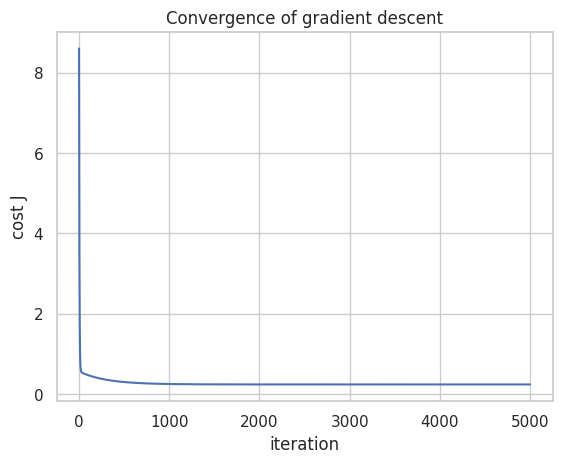

α=0.001: β0=0.345, β1=1.002
α=0.01: β0=0.853, β1=0.973
α=0.1: β0=2.138, β1=0.617
α=0.25: β0=-6979463754357385486430745968502980588560410190058004414464.000, β1=-25198078725087083857398467230578751952245738936179508641792.000


In [8]:
x = np.array([1, 2, 3, 4, 5], dtype=float); y = np.array([2, 4, 5, 4, 5], dtype=float)
b0 = b1 = 0.0; lr_rate = 0.01; n = len(x); history = []
for epoch in range(5000):
    y_hat = b0 + b1 * x
    cost = (1 / (2 * n)) * np.sum((y_hat - y) ** 2)         # J = (1/2n) Σ(ŷ − y)²
    history.append(cost)
    b0 -= lr_rate * (1 / n) * np.sum(y_hat - y)             # β ← β − α ∂J/∂β
    b1 -= lr_rate * (1 / n) * np.sum((y_hat - y) * x)
print(f"Gradient descent -> β0 = {b0:.3f}, β1 = {b1:.3f}   (closed form: 2.2, 0.6)")
plt.plot(history); plt.xlabel("iteration"); plt.ylabel("cost J"); plt.title("Convergence of gradient descent"); plt.show()

# Effect of learning rate
for a in [0.001, 0.01, 0.1, 0.25]:
    b0 = b1 = 0.0
    for _ in range(200):
        yh = b0 + b1 * x
        b0 -= a * np.mean(yh - y); b1 -= a * np.mean((yh - y) * x)
    print(f"α={a}: β0={b0:.3f}, β1={b1:.3f}")

## 4. Regression Evaluation Metrics

In [9]:
y_true = np.array([3, 5, 7, 9]); y_pred = np.array([2.5, 5, 8, 8.5])      # worked example from notes

# --- by hand ---
err = y_true - y_pred
mae = np.mean(np.abs(err)); mse = np.mean(err ** 2); rmse = np.sqrt(mse)
ss_res = np.sum(err ** 2); ss_tot = np.sum((y_true - y_true.mean()) ** 2)
r2 = 1 - ss_res / ss_tot
n, p = len(y_true), 1
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
print(f"MAE={mae:.3f}  MSE={mse:.3f}  RMSE={rmse:.3f}  R²={r2:.3f}  AdjR²={adj_r2:.3f}")

# --- with sklearn ---
print("sklearn:", mean_absolute_error(y_true, y_pred), mean_squared_error(y_true, y_pred),
      np.sqrt(mean_squared_error(y_true, y_pred)), r2_score(y_true, y_pred))

# R² edge cases: predicting the mean gives 0; worse than the mean gives negative
print("Predict-mean R²:", r2_score(y_true, np.full(4, y_true.mean())))
print("Bad model   R²:", r2_score(y_true, np.array([9, 3, 1, 5])))

MAE=0.500  MSE=0.375  RMSE=0.612  R²=0.925  AdjR²=0.888
sklearn: 0.5 0.375 0.6123724356957945 0.925
Predict-mean R²: 0.0
Bad model   R²: -3.5999999999999996


In [10]:
# Effect of an outlier on MAE vs RMSE
a = np.array([10, 12, 11, 13, 12]); good = np.array([10.5, 11.5, 11, 13, 12.5]); bad = good.copy(); bad[-1] = 30
for name, pr in [("no outlier", good), ("with outlier", bad)]:
    print(f"{name:13s} MAE={mean_absolute_error(a, pr):.2f}  RMSE={np.sqrt(mean_squared_error(a, pr)):.2f}")

# Compare models using several metrics
def report(name, yt, yp):
    print(f"{name:20s} MAE={mean_absolute_error(yt, yp):7.2f}  RMSE={np.sqrt(mean_squared_error(yt, yp)):7.2f}  R²={r2_score(yt, yp):.3f}")
Xd = load_diabetes(as_frame=True); Xtr, Xte, ytr, yte = train_test_split(Xd.data, Xd.target, test_size=0.2, random_state=42)
report("Linear Regression", yte, LinearRegression().fit(Xtr, ytr).predict(Xte))
report("Predict the mean", yte, np.full(len(yte), ytr.mean()))

no outlier    MAE=0.30  RMSE=0.39
with outlier  MAE=3.80  RMSE=8.06
Linear Regression    MAE=  42.79  RMSE=  53.85  R²=0.453
Predict the mean     MAE=  64.01  RMSE=  73.22  R²=-0.012


## 5. Logistic Regression

### 5.1 Sigmoid function, odds and log-loss

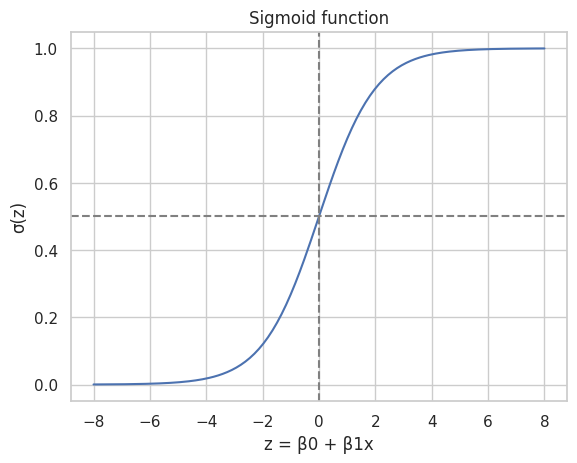

σ(0)= 0.5 | σ(0.5)= 0.622 | σ(-1)= 0.269
hours=2: z=-1.0, P(pass)=0.269 -> Fail   odds=0.368
hours=3: z=0.5, P(pass)=0.622 -> Pass   odds=1.649
Confident & right: 0.01005033585350145
Confident & WRONG: 4.605170185988091


In [11]:
def sigmoid(z): return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 200)
plt.plot(z, sigmoid(z)); plt.axhline(0.5, color="gray", ls="--"); plt.axvline(0, color="gray", ls="--")
plt.xlabel("z = β0 + β1x"); plt.ylabel("σ(z)"); plt.title("Sigmoid function"); plt.show()
print("σ(0)=", sigmoid(0), "| σ(0.5)=", round(sigmoid(0.5), 3), "| σ(-1)=", round(sigmoid(-1), 3))

# Worked example: z = -4 + 1.5 * hours
for h in [2, 3]:
    zz = -4 + 1.5 * h; pr = sigmoid(zz)
    print(f"hours={h}: z={zz}, P(pass)={pr:.3f} -> {'Pass' if pr >= 0.5 else 'Fail'}   odds={pr/(1-pr):.3f}")

# Log loss
def log_loss_manual(y, p): return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
print("Confident & right:", log_loss_manual(np.array([1]), np.array([0.99])))
print("Confident & WRONG:", log_loss_manual(np.array([1]), np.array([0.01])))

### 5.2 Logistic regression from scratch (gradient descent)

β0=-7.159, β1=2.603; decision boundary at x = 2.75 hours


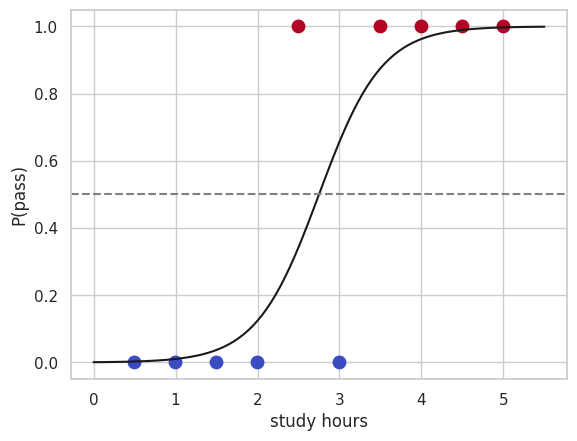

sklearn: -7.159 2.603 | P(pass | 3 hrs) = 0.657


In [12]:
hours = np.array([0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5]); passed = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1])
b0 = b1 = 0.0; alpha = 0.3
for _ in range(10000):
    p = sigmoid(b0 + b1 * hours)
    b0 -= alpha * np.mean(p - passed)                # gradient of log-loss
    b1 -= alpha * np.mean((p - passed) * hours)
print(f"β0={b0:.3f}, β1={b1:.3f}; decision boundary at x = {-b0/b1:.2f} hours")

xs = np.linspace(0, 5.5, 100)
plt.scatter(hours, passed, c=passed, cmap="coolwarm", s=80); plt.plot(xs, sigmoid(b0 + b1 * xs), "k")
plt.axhline(0.5, ls="--", color="gray"); plt.xlabel("study hours"); plt.ylabel("P(pass)"); plt.show()

# Same with sklearn (large C = almost no regularization)
sk = LogisticRegression(C=1e6).fit(hours.reshape(-1, 1), passed)
print("sklearn:", sk.intercept_[0].round(3), sk.coef_[0][0].round(3), "| P(pass | 3 hrs) =", sk.predict_proba([[3]])[0, 1].round(3))

### 5.3 Logistic regression with sklearn (breast cancer dataset)

In [13]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer(as_frame=True); X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)            # fit on train only
X_test_s = scaler.transform(X_test)

clf = LogisticRegression(max_iter=1000, C=1.0).fit(X_train_s, y_train)
y_pred = clf.predict(X_test_s); y_proba = clf.predict_proba(X_test_s)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=data.target_names))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))

Accuracy: 0.9825
[[41  1]
 [ 1 71]]
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

ROC-AUC: 0.9954


In [14]:
# Custom threshold: lower threshold -> higher recall, lower precision
for th in [0.3, 0.5, 0.7, 0.9]:
    yp = (y_proba >= th).astype(int)
    print(f"threshold={th}: precision={precision_score(y_test, yp):.3f}  recall={recall_score(y_test, yp):.3f}  F1={f1_score(y_test, yp):.3f}")

# Coefficients -> odds ratios
coefs = pd.Series(clf.coef_[0], index=X.columns)
print("\nTop positive coefficients:\n", coefs.sort_values().tail(3).round(3))
print("Odds ratio of strongest:", np.exp(coefs.abs().max()).round(2))

# Effect of regularization strength C (smaller C = stronger regularization)
for C_ in [0.001, 0.01, 0.1, 1, 10]:
    m = LogisticRegression(C=C_, max_iter=2000).fit(X_train_s, y_train)
    print(f"C={C_:<6} train acc={m.score(X_train_s, y_train):.3f}  test acc={m.score(X_test_s, y_test):.3f}")

threshold=0.3: precision=0.973  recall=1.000  F1=0.986
threshold=0.5: precision=0.986  recall=0.986  F1=0.986
threshold=0.7: precision=0.985  recall=0.931  F1=0.957
threshold=0.9: precision=0.984  recall=0.847  F1=0.910

Top positive coefficients:
 fractal dimension error    0.438
compactness error          0.647
mean compactness           0.648
dtype: float64
Odds ratio of strongest: 3.51
C=0.001  train acc=0.888  test acc=0.930
C=0.01   train acc=0.956  test acc=0.947
C=0.1    train acc=0.987  test acc=0.974
C=1      train acc=0.989  test acc=0.982
C=10     train acc=0.991  test acc=0.965


In [15]:
# Multinomial (multi-class) logistic regression with softmax on iris
from sklearn.datasets import load_iris
Xi, yi = load_iris(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.2, random_state=0, stratify=yi)
mn = LogisticRegression(max_iter=500).fit(Xtr, ytr)
print("Multi-class accuracy:", mn.score(Xte, yte))
print("Class probabilities (sum to 1):", mn.predict_proba(Xte[:1]).round(3))

def softmax(z): e = np.exp(z - z.max()); return e / e.sum()
print("softmax([2, 1, 0.1]) =", softmax(np.array([2, 1, 0.1])).round(3))

Multi-class accuracy: 1.0
Class probabilities (sum to 1): [[0.977 0.023 0.   ]]
softmax([2, 1, 0.1]) = [0.659 0.242 0.099]


## 6. Introduction to Classification Problems

In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Same data, several classifiers: quick comparison
Xc, yc = load_breast_cancer(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)
sc = StandardScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)

models = {"Logistic Regression": LogisticRegression(max_iter=1000), "k-NN": KNeighborsClassifier(5),
          "Decision Tree": DecisionTreeClassifier(random_state=0), "Naive Bayes": GaussianNB(),
          "SVM": SVC(), "Random Forest": RandomForestClassifier(random_state=0)}
for name, m in models.items():
    m.fit(Xtr_s, ytr); print(f"{name:20s} test accuracy = {m.score(Xte_s, yte):.3f}")

# Types: binary / multi-class / multi-label / imbalanced
print("\nBinary classes:", np.unique(yc), "| Multi-class (iris):", np.unique(yi))
print("Class balance (breast cancer):", np.bincount(yc))

Logistic Regression  test accuracy = 0.982
k-NN                 test accuracy = 0.956
Decision Tree        test accuracy = 0.912
Naive Bayes          test accuracy = 0.930
SVM                  test accuracy = 0.982


Random Forest        test accuracy = 0.956

Binary classes: [0 1] | Multi-class (iris): [0 1 2]
Class balance (breast cancer): [212 357]


## 7. k-Nearest Neighbors (k-NN)

### 7.1 Distance metrics

In [17]:
p = np.array([1, 2, 3]); q = np.array([4, 6, 8])
euclid = np.sqrt(np.sum((p - q) ** 2))
manhat = np.sum(np.abs(p - q))
def minkowski(p, q, r): return np.sum(np.abs(p - q) ** r) ** (1 / r)
hamming = np.sum(np.array(list("karolin")) != np.array(list("kathrin")))
cosine = 1 - p @ q / (np.linalg.norm(p) * np.linalg.norm(q))
print(f"Euclidean={euclid:.3f}  Manhattan={manhat}  Minkowski(p=1)={minkowski(p,q,1)}  Minkowski(p=2)={minkowski(p,q,2):.3f}")
print("Hamming('karolin','kathrin') =", hamming, "| Cosine distance =", round(cosine, 4))

Euclidean=7.071  Manhattan=12  Minkowski(p=1)=12.0  Minkowski(p=2)=7.071
Hamming('karolin','kathrin') = 3 | Cosine distance = 0.0074


### 7.2 k-NN from scratch (worked example from notes)

In [18]:
from collections import Counter

def knn_predict(X_train, y_train, x_new, k=3):
    dists = np.sqrt(((X_train - x_new) ** 2).sum(axis=1))      # Euclidean distance to every point
    idx = np.argsort(dists)[:k]                                 # indices of k nearest
    return Counter(y_train[idx]).most_common(1)[0][0], dists, idx

Xk = np.array([[170, 65], [160, 55], [175, 70], [155, 50]]); yk = np.array(["M", "S", "M", "S"])
label, dists, idx = knn_predict(Xk, yk, np.array([168, 62]), k=3)
print("Distances:", dists.round(2), "| nearest:", yk[idx], "-> prediction:", label)

# Practice problem: query (2,2), A(1,1)->0, B(2,3)->1, C(4,4)->1, k=3
Xp = np.array([[1, 1], [2, 3], [4, 4]]); yp = np.array([0, 1, 1])
print("Practice answer:", knn_predict(Xp, yp, np.array([2, 2]), 3)[0])

Distances: [ 3.61 10.63 10.63 17.69] | nearest: ['M' 'S' 'M'] -> prediction: M
Practice answer: 1


### 7.3 k-NN with sklearn (iris)

In [19]:
iris = load_iris(); X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

sc = StandardScaler()
X_train_s = sc.fit_transform(X_train); X_test_s = sc.transform(X_test)   # scale (essential for k-NN)

knn = KNeighborsClassifier(n_neighbors=5, metric="euclidean", weights="uniform").fit(X_train_s, y_train)
y_pred = knn.predict(X_test_s)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))

# Predict one new flower
new = sc.transform([[5.1, 3.5, 1.4, 0.2]])
print("Predicted:", iris.target_names[knn.predict(new)[0]], "| probabilities:", knn.predict_proba(new))

# Other options: distance-weighted voting and other metrics
for w in ["uniform", "distance"]:
    for met in ["euclidean", "manhattan"]:
        a = KNeighborsClassifier(5, weights=w, metric=met).fit(X_train_s, y_train).score(X_test_s, y_test)
        print(f"weights={w:8s} metric={met:10s} accuracy={a:.3f}")

Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Predicted: setosa | probabilities: [[1. 0. 0.]]
weights=uniform  metric=euclidean  accuracy=0.933
weights=uniform  metric=manhattan  accuracy=0.933
weights=distance metric=euclidean  accuracy=0.967
weights=distance metric=manhattan  accuracy=0.967


### 7.4 Choosing k (cross-validation) and why scaling matters

Best k by 5-fold CV: 5 | CV accuracy: 0.967


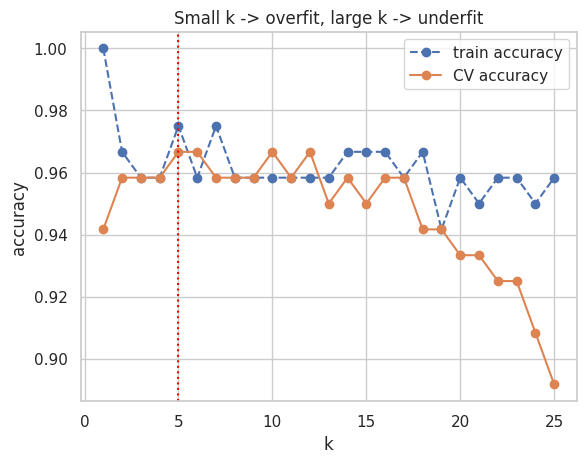

Unscaled accuracy: 0.5
Scaled   accuracy: 0.858


In [20]:
ks = range(1, 26)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train, cv=5).mean() for k in ks]
train_scores = [KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train).score(X_train_s, y_train) for k in ks]
best_k = ks[int(np.argmax(cv_scores))]
print("Best k by 5-fold CV:", best_k, "| CV accuracy:", round(max(cv_scores), 3))

plt.plot(ks, train_scores, "o--", label="train accuracy"); plt.plot(ks, cv_scores, "o-", label="CV accuracy")
plt.axvline(best_k, color="red", ls=":"); plt.xlabel("k"); plt.ylabel("accuracy")
plt.title("Small k -> overfit, large k -> underfit"); plt.legend(); plt.show()

# Why scaling matters: salary (large range) vs age (small range)
from sklearn.datasets import make_classification
Xw, yw = make_classification(n_samples=400, n_features=4, n_informative=3, n_redundant=0, random_state=0)
Xw[:, 0] *= 1000                                                  # one feature on a huge scale
Xa, Xb, ya, yb = train_test_split(Xw, yw, test_size=0.3, random_state=0)
print("Unscaled accuracy:", round(KNeighborsClassifier(5).fit(Xa, ya).score(Xb, yb), 3))
s2 = StandardScaler().fit(Xa)
print("Scaled   accuracy:", round(KNeighborsClassifier(5).fit(s2.transform(Xa), ya).score(s2.transform(Xb), yb), 3))

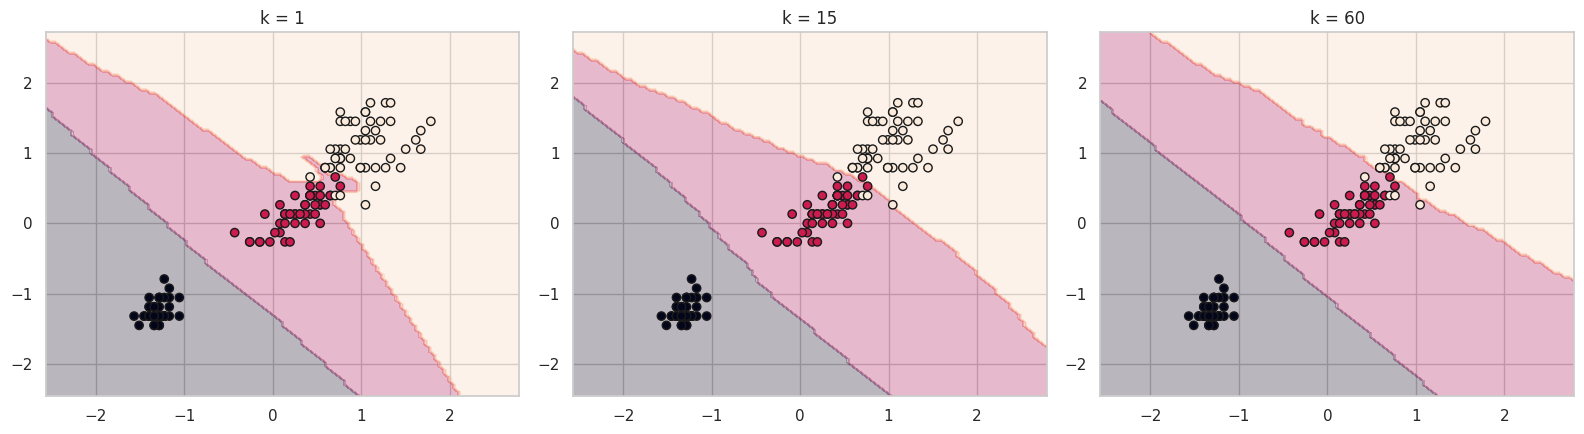

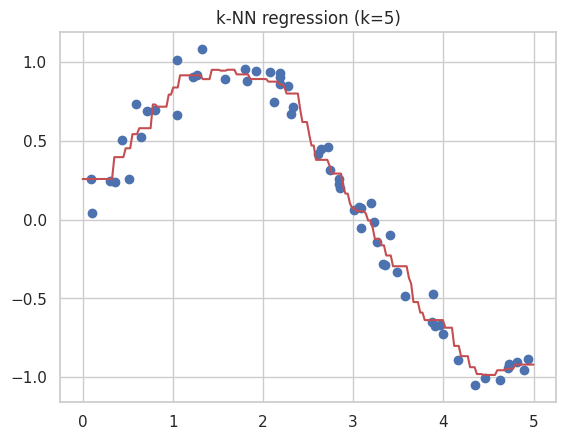

In [21]:
# Decision boundary for different k (2 features so it can be drawn)
from sklearn.inspection import DecisionBoundaryDisplay
X2 = StandardScaler().fit_transform(X[:, 2:4])                    # petal length & width
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, k in zip(ax, [1, 15, 60]):
    m = KNeighborsClassifier(k).fit(X2, y)
    DecisionBoundaryDisplay.from_estimator(m, X2, ax=a, alpha=0.3, response_method="predict")
    a.scatter(X2[:, 0], X2[:, 1], c=y, edgecolor="k"); a.set_title(f"k = {k}")
plt.tight_layout(); plt.show()

# k-NN for regression (average of neighbours)
from sklearn.neighbors import KNeighborsRegressor
xr = np.sort(np.random.RandomState(0).rand(60, 1) * 5, axis=0); yr = np.sin(xr).ravel() + np.random.RandomState(1).normal(0, .1, 60)
kr = KNeighborsRegressor(5).fit(xr, yr); g = np.linspace(0, 5, 200).reshape(-1, 1)
plt.scatter(xr, yr); plt.plot(g, kr.predict(g), "r"); plt.title("k-NN regression (k=5)"); plt.show()

## 8. Performance Metrics for Classification

### 8.1 Confusion matrix and metrics by hand (worked example: TP=40, FP=10, FN=20, TN=30)

In [22]:
TP, FP, FN, TN = 40, 10, 20, 30
accuracy    = (TP + TN) / (TP + TN + FP + FN)
precision   = TP / (TP + FP)
recall      = TP / (TP + FN)
specificity = TN / (TN + FP)
f1          = 2 * precision * recall / (precision + recall)
fpr         = FP / (FP + TN)
print(f"Accuracy={accuracy:.3f}  Precision={precision:.3f}  Recall={recall:.3f}  Specificity={specificity:.3f}  F1={f1:.3f}  FPR={fpr:.3f}")

# Practice: TP=50, FP=5, FN=10, TN=35
t, f_p, f_n, tn_ = 50, 5, 10, 35
P, R = t / (t + f_p), t / (t + f_n)
print(f"Practice -> Acc={(t+tn_)/100:.2f}  P={P:.3f}  R={R:.3f}  F1={2*P*R/(P+R):.3f}")

# Accuracy paradox: 99% negatives, model always predicts 0
yt = np.array([0] * 990 + [1] * 10); yp = np.zeros(1000, dtype=int)
print("\nAccuracy paradox -> accuracy:", accuracy_score(yt, yp), "| recall:", recall_score(yt, yp), "| F1:", f1_score(yt, yp, zero_division=0))

Accuracy=0.700  Precision=0.800  Recall=0.667  Specificity=0.750  F1=0.727  FPR=0.250
Practice -> Acc=0.85  P=0.909  R=0.833  F1=0.870

Accuracy paradox -> accuracy: 0.99 | recall: 0.0 | F1: 0.0


### 8.2 With sklearn

TP, FP, FN, TN = 4 1 1 4
Accuracy : 0.8
Precision: 0.8
Recall   : 0.8
F1       : 0.8
              precision    recall  f1-score   support

           0       0.80      0.80      0.80         5
           1       0.80      0.80      0.80         5

    accuracy                           0.80        10
   macro avg       0.80      0.80      0.80        10
weighted avg       0.80      0.80      0.80        10



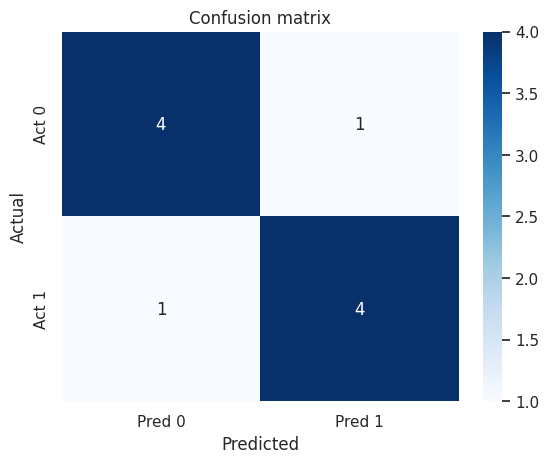

In [23]:
y_true = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 1, 0]

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()
print("TP, FP, FN, TN =", tp, fp, fn, tn)
print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall   :", recall_score(y_true, y_pred))
print("F1       :", f1_score(y_true, y_pred))
print(classification_report(y_true, y_pred))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Pred 0", "Pred 1"], yticklabels=["Act 0", "Act 1"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix"); plt.show()

### 8.3 ROC curve, AUC and the precision-recall trade-off

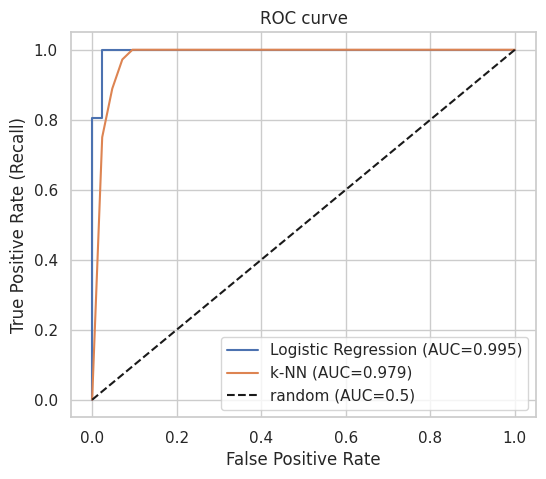

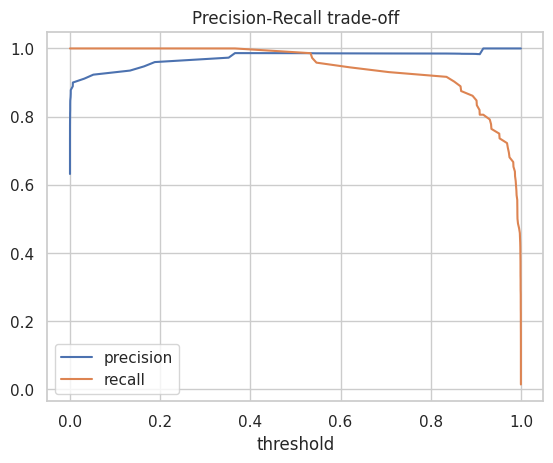

In [24]:
# Use probabilities from two classifiers on the breast cancer data
Xb, yb = load_breast_cancer(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=0.2, random_state=42, stratify=yb)
s = StandardScaler().fit(Xtr)
lg = LogisticRegression(max_iter=1000).fit(s.transform(Xtr), ytr)
kn = KNeighborsClassifier(5).fit(s.transform(Xtr), ytr)

plt.figure(figsize=(6, 5))
for name, m in [("Logistic Regression", lg), ("k-NN", kn)]:
    proba = m.predict_proba(s.transform(Xte))[:, 1]
    fpr, tpr, _ = roc_curve(yte, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yte, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="random (AUC=0.5)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)"); plt.title("ROC curve"); plt.legend(); plt.show()

from sklearn.metrics import precision_recall_curve
pr, rc, th = precision_recall_curve(yte, lg.predict_proba(s.transform(Xte))[:, 1])
plt.plot(th, pr[:-1], label="precision"); plt.plot(th, rc[:-1], label="recall")
plt.xlabel("threshold"); plt.title("Precision-Recall trade-off"); plt.legend(); plt.show()

### 8.4 Multi-class metrics (macro / weighted / micro averaging)

In [25]:
Xi, yi = load_iris(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.3, random_state=3, stratify=yi)
sc = StandardScaler().fit(Xtr)
yp = KNeighborsClassifier(7).fit(sc.transform(Xtr), ytr).predict(sc.transform(Xte))

print(confusion_matrix(yte, yp))
for avg in ["macro", "weighted", "micro"]:
    print(f"{avg:9s} precision={precision_score(yte, yp, average=avg):.3f}  recall={recall_score(yte, yp, average=avg):.3f}  F1={f1_score(yte, yp, average=avg):.3f}")
print(classification_report(yte, yp, target_names=load_iris().target_names))

# Cross-validated metrics (more reliable than one split)
from sklearn.model_selection import cross_validate
res = cross_validate(KNeighborsClassifier(7), sc.transform(Xi), yi, cv=5, scoring=["accuracy", "precision_macro", "recall_macro", "f1_macro"])
print({k: v.mean().round(3) for k, v in res.items() if k.startswith("test_")})

[[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]
macro     precision=0.979  recall=0.978  F1=0.978
weighted  precision=0.979  recall=0.978  F1=0.978
micro     precision=0.978  recall=0.978  F1=0.978
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.94      1.00      0.97        15
   virginica       1.00      0.93      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45

{'test_accuracy': np.float64(0.953), 'test_precision_macro': np.float64(0.957), 'test_recall_macro': np.float64(0.953), 'test_f1_macro': np.float64(0.953)}


## 9. Putting it all together: complete classification pipeline
Scaling inside a `Pipeline` prevents data leakage during cross-validation.

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

Xb, yb = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(Xb, yb, test_size=0.2, random_state=42, stratify=yb)

pipe = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier())])
grid = GridSearchCV(pipe, {"knn__n_neighbors": range(1, 21, 2), "knn__weights": ["uniform", "distance"]},
                    cv=5, scoring="f1")
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_, "| best CV F1:", round(grid.best_score_, 3))

best = grid.best_estimator_
y_pred = best.predict(X_test)
print(classification_report(y_test, y_pred))

Best params: {'knn__n_neighbors': 7, 'knn__weights': 'uniform'} | best CV F1: 0.977
              precision    recall  f1-score   support

           0       1.00      0.93      0.96        42
           1       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



## 10. Practice answers (from notes)
1. Fit a line for x=[1,2,3,4], y=[3,5,7,9] → ŷ = 1 + 2x, R² = 1
2. Logistic z = −6 + 2x at x = 3 → P = 0.5

In [27]:
x = np.array([1, 2, 3, 4]); y = np.array([3, 5, 7, 9])
b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2); b0 = y.mean() - b1 * x.mean()
print("Line: ŷ =", b0, "+", b1, "x | R² =", r2_score(y, b0 + b1 * x))
print("P(y=1) at x=3:", 1 / (1 + np.exp(-(-6 + 2 * 3))))

Line: ŷ = 1.0 + 2.0 x | R² = 1.0
P(y=1) at x=3: 0.5
